
# THÀNH VIÊN 3 – PHÂN LỚP DỮ LIỆU TUYỂN DỤNG

## Dự đoán mức lương dựa trên kỹ năng và kinh nghiệm

### Nội dung thực hiện

- 2.5. Phân lớp bằng Decision Tree và Random Forest
- 2.6. Đánh giá mô hình và rút trích luật phân lớp
- 3 Thảo luận, khuyến nghị và tổng hợp tri thức

**Nguồn dữ liệu:** clean_data.csv

**Mục tiêu:** Xây dựng mô hình dự đoán nhóm lương
của các vị trí tuyển dụng ngành Data dựa trên
60 kỹ năng và số năm kinh nghiệm.



In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)




## 2.5. Phân lớp bằng Decision Tree và Random Forest

### 2.5.1. Giới thiệu bài toán và kiểm tra dữ liệu

Bài toán nhằm dự đoán khoảng lương của các vị trí
tuyển dụng thuộc ngành Data dựa trên các yêu cầu
về kỹ năng chuyên môn và số năm kinh nghiệm.

Sử dụng hai thuật toán phân lớp:
- Decision Tree (Cây quyết định).
- Random Forest (Rừng ngẫu nhiên).

Nhãn phân lớp gồm ba nhóm:
- Dưới 15M.
- 15M - 30M.
- Trên 30M.

Trước khi huấn luyện, tiến hành kiểm tra cấu trúc,
kích thước và chất lượng dữ liệu đầu vào.


In [12]:

# Đọc dữ liệu đã làm sạch
data_path = Path(
    r"D:\project_datamining\crawl-data-job-it-\data\clean_data.csv"
)

df = pd.read_csv(
    data_path,
    encoding="utf-8-sig"
)

# Hiển thị thông tin tổng quan
print("Số tin tuyển dụng:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

# Xác định các cột kỹ năng
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

print("Số kỹ năng:", len(skill_cols))

# Kiểm tra dữ liệu thiếu ở các cột cần thiết
required_cols = (
    skill_cols
    + ["So_Nam_Kinh_Nghiem", "Khoang_Luong_Phan_Lop"]
)

print(
    "Số giá trị thiếu trong các cột cần dùng:",
    df[required_cols].isna().sum().sum()
)

# Xem 5 dòng dữ liệu đầu tiên
display(df.head())


Số tin tuyển dụng: 1547
Số thuộc tính: 85
Số kỹ năng: 60
Số giá trị thiếu trong các cột cần dùng: 0


,Job_ID,Site,Tieu_De,Cong_Ty,Nhom_Nganh_Data,Dia_Diem_Goc,Dia_Diem_Chuan,Hinh_Thuc_Lam_Viec_Goc,Mo_Hinh_Lam_Viec,Kinh_Nghiem_Goc,So_Nam_Kinh_Nghiem,Cap_Bac,Muc_Luong_Goc,Trang_Thai_Luong,Luong_Min,Luong_Max,Luong_Trung_Binh,Luong_Trung_Binh_Imputed,Khoang_Luong_Phan_Lop,Danh_Sach_Ky_Nang,So_Luong_Ky_Nang,Mo_Ta_Cong_Viec,Mo_Ta_Lam_Sach,URL_Goc,Timestamp,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp,Skill_JavaScript,Skill_Bash_Shell,Skill_PowerBI,Skill_Tableau,Skill_Looker,Skill_Excel,Skill_Statistics,Skill_AB_Testing,Skill_Data_Storytelling,Skill_Spark,Skill_Hadoop,Skill_Kafka,Skill_Airflow,Skill_dbt,Skill_ETL,Skill_Data_Warehouse,Skill_Data_Lake,Skill_Data_Modeling,Skill_Machine_Learning,Skill_Deep_Learning,Skill_Pandas,Skill_NumPy,Skill_Scikit_Learn,Skill_PyTorch,Skill_TensorFlow,Skill_NLP,Skill_Computer_Vision,Skill_LLM_GenAI,Skill_MLOps,Skill_PostgreSQL,Skill_MySQL,Skill_SQL_Server,Skill_Oracle,Skill_MongoDB,Skill_Redis,Skill_Elasticsearch,Skill_BigQuery,Skill_Snowflake,Skill_Databricks,Skill_Redshift,Skill_Cloud_AWS,Skill_Cloud_Azure,Skill_Cloud_GCP,Skill_Docker,Skill_Kubernetes,Skill_Git,Skill_Linux,Skill_CI_CD,Skill_English,Skill_Communication,Skill_Problem_Solving,Skill_Teamwork,Skill_Agile_Scrum,Skill_Data_Governance
0,DATA_0001,topcv,Chuyên Viên Dữ Liệu Lớn (Big Data),ProNgân hàng TMCP Đông Nam Á - SEABANK,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,1 năm,1.0,Junior,Thoả thuận,Thoa_Thuan,NaN,NaN,NaN,19.50,15M - 30M,Python; SQL; Scala; PowerBI; Tableau; Looker; ...,21,## Company\n\nSoutheast Asia Commercial Joint ...,## company southeast asia commercial joint sto...,https://www.topcv.vn/viec-lam/chuyen-vien-du-l...,2026-11-13 10:45:00,1,1,0,1,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,DATA_0002,topdev,DATA ENGINEER / DATA PLATFORM ENGINEER,CÔNG TY TNHH AZIWORLD,Data Engineer / Big Data,Việt Nam,Khác,On-site (Toàn thời gian),On-site,3 years of experience,3.0,Middle,Login to view salary,Thoa_Thuan,NaN,NaN,NaN,26.50,15M - 30M,Python; SQL; Looker; Data_Storytelling; Spark;...,25,## Company\n\nAzIWorld Company Limited (CÔNG T...,## company aziworld company limited tnhh aziwo...,https://topdev.vn/detail-jobs/data-engineer-da...,2026-10-17 09:00:00,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1
2,DATA_0003,topcv,Lead Data Engineer,CÔNG TY CỔ PHẦN CÔNG NGHỆ SICIX,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,3 năm,6.0,Lead,20 - 40 triệu,Co_Cong_Bo,20.0,40.0,30.00,30.00,15M - 30M,Python; SQL; Scala; Java; Statistics; Data_Sto...,24,## Company\n\nSICIX Technology Joint Stock Com...,## company sicix technology joint stock compan...,https://www.topcv.vn/viec-lam/lead-data-engine...,2026-11-13 10:45:00,1,1,0,1,1,0,0,0,0,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,1
3,DATA_0004,vietnamworks,Database Administrator,Navigos Group,Database / Data Platform & Ops,Hồ Chí Minh,TP.HCM,On-site (Toàn thời gian),On-site,Experienced (non-manager),2.5,Middle,"$ 1,000-1,500 /tháng",Co_Cong_Bo,25.4,38.1,31.75,31.75,Trên 30M,Python; SQL; Bash_Shell; PowerBI; Tableau; Loo...,26,## Company\n\nNavigos Group is a technology co...,## company navigos group technology company op...,https://www.vietnamworks.com/database-administ...,2026-10-23 08:01:45,1,1,0,0,0,0,0,1,1,1,1,0,0,0,1,0,0,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,1
4,DATA_0005,vietnamworks,Trưởng Phòng Kiến Trúc Và Nền Tảng Dữ Liệu,Ngân Hàng TMCP Phương Đông ( OCB ),Data Engineer / Big Data,Hồ Chí Minh,TP.HCM,On-site (Full-time),On-site,Manager,6.0,Lead,Thương lượng,Thoa_Thuan,NaN,NaN,NaN,30.00,15M - 30M,Python; SQL; Data_Storytelling; Spark; Hadoop;...,24,## Company\n\nOrient Commercial Joint Stock Ba...,## company orient commercial joint stock bank ...,https://www.vietnamworks.com/t


#### Nhận xét

- Bộ dữ liệu gồm 1.547 tin tuyển dụng và 85 thuộc tính.
- Có 60 thuộc tính kỹ năng được mã hóa dưới dạng
  nhị phân (0 và 1).
- Thuộc tính So_Nam_Kinh_Nghiem biểu diễn số năm
  kinh nghiệm được yêu cầu trong tin tuyển dụng.
- Khoang_Luong_Phan_Lop là nhãn cần dự đoán,
  gồm ba nhóm mức lương.
- Các thuộc tính dự kiến sử dụng để huấn luyện
  không có giá trị thiếu.

**Kết luận:** Dữ liệu có đủ các thuộc tính cần thiết
để bước đầu xây dựng mô hình phân lớp.
Tuy nhiên, cần xem xét việc nội suy các mức lương
không được công bố trước khi đánh giá kết quả mô hình.



### 2.5.2. Chuẩn bị dữ liệu đầu vào X và nhãn y

Trong bài toán phân lớp, dữ liệu được chia thành
hai thành phần chính:

- **X (Features):** Tập thuộc tính đầu vào gồm
  60 kỹ năng công nghệ và số năm kinh nghiệm.
- **y (Target):** Nhãn phân lớp khoảng lương,
  gồm ba nhóm: Dưới 15M, 15M - 30M và Trên 30M.

Các kỹ năng được biểu diễn dưới dạng nhị phân:
- 1: Tin tuyển dụng có yêu cầu kỹ năng.
- 0: Tin tuyển dụng không ghi nhận yêu cầu kỹ năng.

Mục tiêu của bước này là lựa chọn các thuộc tính
phù hợp để phục vụ quá trình huấn luyện mô hình
Decision Tree và Random Forest.

Những thuộc tính liên quan trực tiếp đến mức lương
như Luong_Min, Luong_Max và Luong_Trung_Binh_Imputed
không được đưa vào X nhằm tránh rò rỉ thông tin
(Data Leakage).


In [13]:

# ============================================
# 2.5.2. CHUẨN BỊ DỮ LIỆU X VÀ y
# ============================================

# Bước 1: Lấy danh sách 60 cột kỹ năng
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

# Bước 2: Tạo danh sách đặc trưng đầu vào
feature_cols = skill_cols + ["So_Nam_Kinh_Nghiem"]

# Bước 3: Tạo tập dữ liệu đầu vào X
X = df[feature_cols].copy()

# Bước 4: Tạo nhãn phân lớp y
y = df["Khoang_Luong_Phan_Lop"].copy()

# Bước 5: Kiểm tra kích thước
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

# Bước 6: Kiểm tra dữ liệu thiếu
print("\nGiá trị thiếu trong X:", X.isna().sum().sum())
print("Giá trị thiếu trong y:", y.isna().sum())

# Bước 7: Hiển thị dữ liệu
print("\nVí dụ dữ liệu đầu vào X:")
display(X.iloc[:5, :6])

print("\nPhân bố nhãn y:")
print(y.value_counts())


Kích thước X: (1547, 61)
Kích thước y: (1547,)

Giá trị thiếu trong X: 0
Giá trị thiếu trong y: 0

Ví dụ dữ liệu đầu vào X:


,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp
0,1,1,0,1,0,0
1,1,1,0,0,0,0
2,1,1,0,1,1,0
3,1,1,0,0,0,0
4,1,1,0,0,0,0



Phân bố nhãn y:
Khoang_Luong_Phan_Lop
15M - 30M    746
Trên 30M     602
Dưới 15M     199
Name: count, dtype: int64



#### Nhận xét

- Tập dữ liệu đầu vào X gồm 1.547 quan sát và
  61 thuộc tính, bao gồm 60 kỹ năng công nghệ
  và một thuộc tính số năm kinh nghiệm.

- Các thuộc tính kỹ năng đã được mã hóa dưới
  dạng nhị phân (0 và 1), phù hợp với hai
  thuật toán Decision Tree và Random Forest.

- Nhãn y gồm ba nhóm khoảng lương:
  Dưới 15M, 15M - 30M và Trên 30M.

- Nhóm 15M - 30M chiếm tỷ lệ lớn nhất với
  746 tin tuyển dụng (48,2%), trong khi nhóm
  Dưới 15M có ít quan sát nhất với 199 tin
  (12,9%).

- Không phát hiện giá trị thiếu trong các
  thuộc tính X và nhãn y.

- Phân bố nhãn chưa đồng đều giữa ba lớp.
  Vì vậy, cần chú ý đến Precision, Recall,
  F1-score và ma trận nhầm lẫn khi đánh giá
  mô hình thay vì chỉ sử dụng Accuracy.

**Kết luận:** Dữ liệu X và y đã được chuẩn bị
để thực hiện bước chia tập huấn luyện và
tập kiểm tra. Chất lượng nhãn lương nội suy
cần tiếp tục được xem xét khi đánh giá mô hình.



### 2.5.3. Chia tập dữ liệu huấn luyện và kiểm tra

Để đánh giá khả năng dự đoán của mô hình trên
dữ liệu chưa được sử dụng trong quá trình học,
tập dữ liệu được chia thành hai phần:

- **Tập huấn luyện (Training Set): 80%**
  Dùng để huấn luyện mô hình Decision Tree
  và Random Forest.

- **Tập kiểm tra (Testing Set): 20%**
  Dùng để đánh giá khả năng dự đoán
  của mô hình sau khi huấn luyện.

Quá trình chia dữ liệu sử dụng hàm
train_test_split() trong thư viện scikit-learn.

Các tham số được thiết lập:

- test_size=0.2: Sử dụng 20% dữ liệu để kiểm tra.
- random_state=42: Cố định kết quả chia dữ liệu,
  đảm bảo khả năng tái lập thí nghiệm.
- stratify=y: Duy trì tỷ lệ các nhóm lương
  tương đối đồng đều giữa tập Train và Test.

Việc phân chia này giúp hạn chế đánh giá
quá lạc quan khi kiểm tra mô hình.


In [15]:

# ============================================
# 2.5.3. CHIA TẬP TRAIN / TEST
# ============================================

from sklearn.model_selection import train_test_split

# Bước 1: Chia dữ liệu theo tỷ lệ 80% - 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Bước 2: Kiểm tra kích thước các tập
print("Kích thước tập huấn luyện:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nKích thước tập kiểm tra:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Bước 3: Kiểm tra tỷ lệ các nhóm lương
print("\nPhân bố nhãn tập Train:")
print(y_train.value_counts())

print("\nPhân bố nhãn tập Test:")
print(y_test.value_counts())

# Bước 4: So sánh tỷ lệ nhãn giữa các tập
ty_le = pd.DataFrame({
    "Toàn bộ (%)": y.value_counts(normalize=True) * 100,
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100
})

print("\nSo sánh tỷ lệ các nhóm lương:")
display(ty_le.round(2))


Kích thước tập huấn luyện:
X_train: (1237, 61)
y_train: (1237,)

Kích thước tập kiểm tra:
X_test: (310, 61)
y_test: (310,)

Phân bố nhãn tập Train:
Khoang_Luong_Phan_Lop
15M - 30M    597
Trên 30M     481
Dưới 15M     159
Name: count, dtype: int64

Phân bố nhãn tập Test:
Khoang_Luong_Phan_Lop
15M - 30M    149
Trên 30M     121
Dưới 15M      40
Name: count, dtype: int64

So sánh tỷ lệ các nhóm lương:


,Toàn bộ (%),Train (%),Test (%)
Khoang_Luong_Phan_Lop,,,
15M - 30M,48.22,48.26,48.06
Trên 30M,38.91,38.88,39.03
Dưới 15M,12.86,12.85,12.90



#### Nhận xét

- Bộ dữ liệu gồm 1.547 tin tuyển dụng đã được
  chia thành hai tập theo tỷ lệ 80% - 20%.

- Tập huấn luyện (Train) gồm 1.237 quan sát,
  được sử dụng để huấn luyện hai thuật toán
  Decision Tree và Random Forest.

- Tập kiểm tra (Test) gồm 310 quan sát,
  được sử dụng để đánh giá khả năng dự đoán
  trên dữ liệu chưa tham gia huấn luyện.

- Cả hai tập đều có 61 thuộc tính đầu vào,
  bao gồm 60 kỹ năng và số năm kinh nghiệm.

- Tham số stratify=y giúp duy trì tỷ lệ
  các nhóm lương tương đối ổn định giữa
  tập Train và Test.

- Nhóm lương 15M - 30M vẫn chiếm tỷ lệ lớn
  nhất trong cả hai tập dữ liệu.

- Tham số random_state=42 được sử dụng
  nhằm đảm bảo tính tái lập của thí nghiệm.

**Kết luận:** Dữ liệu đã được chia thành
tập huấn luyện và tập kiểm tra. Hai tập
duy trì tỷ lệ phân bố nhãn tương đối
tương đồng, sẵn sàng cho bước xây dựng
mô hình phân lớp.



### 2.5.4. Xây dựng mô hình Decision Tree

Decision Tree (Cây quyết định) là thuật toán
học máy có giám sát, được sử dụng để thực hiện
bài toán phân lớp.

Thuật toán xây dựng các quy tắc phân chia dữ liệu
dựa trên những thuộc tính đầu vào, nhằm dự đoán
nhãn phân lớp tương ứng.

Trong bài toán này, Decision Tree được sử dụng
để dự đoán khoảng lương của tin tuyển dụng
dựa trên 60 kỹ năng công nghệ và số năm kinh nghiệm.

Mô hình được xây dựng bằng lớp
DecisionTreeClassifier của thư viện scikit-learn.

Các tham số ban đầu:

- criterion="gini": Sử dụng chỉ số Gini
  để đánh giá chất lượng phân chia dữ liệu.
- max_depth=5: Giới hạn độ sâu tối đa của cây.
- min_samples_leaf=10: Mỗi nút lá phải có
  ít nhất 10 quan sát.
- random_state=42: Cố định yếu tố ngẫu nhiên
  để đảm bảo khả năng tái lập thí nghiệm.

Mô hình được huấn luyện trên tập Train (80%)
và dự đoán trên tập Test (20%) đã được chia
ở mục 2.5.3.


In [16]:

# ============================================
# 2.5.4. XÂY DỰNG MÔ HÌNH DECISION TREE
# ============================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Bước 1: Khởi tạo mô hình Decision Tree
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)

# Bước 2: Huấn luyện mô hình trên tập Train
dt_model.fit(X_train, y_train)

# Bước 3: Dự đoán nhóm lương trên tập Train
y_train_pred_dt = dt_model.predict(X_train)

# Bước 4: Dự đoán nhóm lương trên tập Test
y_pred_dt = dt_model.predict(X_test)

# Bước 5: Tính độ chính xác
train_acc_dt = accuracy_score(
    y_train, y_train_pred_dt
)

test_acc_dt = accuracy_score(
    y_test, y_pred_dt
)

# Bước 6: Hiển thị kết quả
print("DECISION TREE CLASSIFIER")
print("-----------------------------")

print(f"Accuracy Train: {train_acc_dt:.4f}")
print(f"Accuracy Test : {test_acc_dt:.4f}")

print("\nĐộ sâu thực tế:", dt_model.get_depth())
print("Số nút lá:", dt_model.get_n_leaves())


DECISION TREE CLASSIFIER
-----------------------------
Accuracy Train: 0.8310
Accuracy Test : 0.7548

Độ sâu thực tế: 5
Số nút lá: 27


## BẢNG SO SÁNH KẾT QUẢ DỰ ĐOÁN

In [17]:

# ============================================
# SO SÁNH KẾT QUẢ DỰ ĐOÁN
# ============================================

# Tạo bảng kết quả
ket_qua_dt = pd.DataFrame({
    "Thuc_Te": y_test.to_numpy(),
    "Du_Doan": y_pred_dt
})

# Xác định dự đoán đúng hay sai
ket_qua_dt["Ket_Qua"] = (
    ket_qua_dt["Thuc_Te"] == ket_qua_dt["Du_Doan"]
)

# Hiển thị 10 dòng đầu tiên
display(ket_qua_dt.head(10))

# Thống kê số dự đoán đúng và sai
print("\nSố dự đoán đúng:",
      ket_qua_dt["Ket_Qua"].sum())

print("Số dự đoán sai:",
      (~ket_qua_dt["Ket_Qua"]).sum())


,Thuc_Te,Du_Doan,Ket_Qua
0,15M - 30M,15M - 30M,True
1,Trên 30M,Trên 30M,True
2,Trên 30M,Trên 30M,True
3,15M - 30M,15M - 30M,True
4,Trên 30M,15M - 30M,False
5,15M - 30M,15M - 30M,True
6,15M - 30M,15M - 30M,True
7,Trên 30M,Trên 30M,True
8,Dưới 15M,Dưới 15M,True
9,Dưới 15M,Dưới 15M,True



Số dự đoán đúng: 234
Số dự đoán sai: 76



#### Nhận xét

- Mô hình Decision Tree được huấn luyện
  trên 1.237 tin tuyển dụng với 61 thuộc tính
  đầu vào, bao gồm 60 kỹ năng và số năm
  kinh nghiệm.

- Thuật toán sử dụng tiêu chí Gini để
  lựa chọn các điểm phân chia dữ liệu.

- Độ sâu tối đa được giới hạn bằng 5 và
  mỗi nút lá yêu cầu ít nhất 10 quan sát,
  nhằm hạn chế độ phức tạp của mô hình.

- Mô hình đạt Accuracy trên tập Train
  khoảng 83,10% và trên tập Test khoảng 75,48%.

- Kết quả cho thấy mô hình có khả năng học
  được mối quan hệ giữa các đặc trưng đầu vào
  và nhãn phân lớp khoảng lương.

- Accuracy trên tập Test thấp hơn tập Train
  khoảng 7,62 điểm phần trăm, cho thấy cần
  tiếp tục kiểm tra khả năng tổng quát hóa
  và nguy cơ overfitting.

- Các tham số hiện tại chỉ là cấu hình
  thử nghiệm ban đầu, chưa phải cấu hình
  được tối ưu hóa.

**Kết luận:** Mô hình Decision Tree đã được
xây dựng và huấn luyện thành công, bước đầu
cho thấy khả năng dự đoán các nhóm lương
trong bộ dữ liệu đã xử lý. Cần tiếp tục
đánh giá bằng Precision, Recall, F1-score
và ma trận nhầm lẫn để hiểu rõ hiệu quả
dự đoán trên từng nhóm lương.



### 2.5.5. Xây dựng mô hình Random Forest

Random Forest (Rừng ngẫu nhiên) là thuật toán học
máy có giám sát thuộc nhóm Ensemble Learning,
kết hợp nhiều cây quyết định để đưa ra kết quả
phân lớp cuối cùng.

Thuật toán sử dụng phương pháp Bootstrap Sampling
để tạo các tập mẫu huấn luyện khác nhau, đồng thời
lựa chọn ngẫu nhiên một tập con đặc trưng tại
các nút phân chia.

Trong bài toán này, Random Forest được sử dụng
để dự đoán khoảng lương tuyển dụng dựa trên
60 kỹ năng công nghệ và số năm kinh nghiệm.

Mô hình được xây dựng bằng
`RandomForestClassifier` của thư viện scikit-learn.

Các tham số được thiết lập:

- `n_estimators=200`: Sử dụng 200 cây quyết định.
- `criterion="gini"`: Sử dụng chỉ số Gini.
- `max_depth=10`: Giới hạn độ sâu tối đa của cây.
- `min_samples_leaf=5`: Yêu cầu tối thiểu
  5 quan sát tại mỗi nút lá.
- `max_features="sqrt"`: Lựa chọn ngẫu nhiên
  một tập con đặc trưng tại mỗi lần phân chia.
- `random_state=42`: Đảm bảo tính tái lập.
- `n_jobs=-1`: Tăng tốc quá trình huấn luyện.

Mô hình được huấn luyện trên tập Train và
được đánh giá sơ bộ trên tập Test đã chia
ở mục 2.5.3.

Mục tiêu là kiểm tra khả năng phân lớp của
Random Forest và làm cơ sở so sánh với
Decision Tree ở phần đánh giá mô hình.


In [18]:

# ============================================
# 2.5.5. XÂY DỰNG MÔ HÌNH RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Bước 1: Khởi tạo mô hình Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Bước 2: Huấn luyện mô hình trên tập Train
rf_model.fit(X_train, y_train)

# Bước 3: Dự đoán trên tập Train
y_train_pred_rf = rf_model.predict(X_train)

# Bước 4: Dự đoán trên tập Test
y_pred_rf = rf_model.predict(X_test)

# Bước 5: Tính Accuracy
train_acc_rf = accuracy_score(
    y_train, y_train_pred_rf
)

test_acc_rf = accuracy_score(
    y_test, y_pred_rf
)

# Bước 6: Hiển thị kết quả
print("RANDOM FOREST CLASSIFIER")
print("-----------------------------")

print(f"Accuracy Train: {train_acc_rf:.4f}")
print(f"Accuracy Test : {test_acc_rf:.4f}")

print("\nSố cây trong rừng:",
      len(rf_model.estimators_))

print("Số đặc trưng đầu vào:",
      rf_model.n_features_in_)


RANDOM FOREST CLASSIFIER
-----------------------------
Accuracy Train: 0.8391
Accuracy Test : 0.7355

Số cây trong rừng: 200
Số đặc trưng đầu vào: 61


## KIỂM TRA KẾT QUẢ DỰ ĐOÁN RANDOM FOREST

In [19]:

# ============================================
# KIỂM TRA KẾT QUẢ DỰ ĐOÁN RANDOM FOREST
# ============================================

# Tạo bảng kết quả
ket_qua_rf = pd.DataFrame({
    "Thuc_Te": y_test.to_numpy(),
    "Du_Doan": y_pred_rf
})

# Kiểm tra dự đoán đúng hay sai
ket_qua_rf["Ket_Qua"] = (
    ket_qua_rf["Thuc_Te"] == ket_qua_rf["Du_Doan"]
)

# Hiển thị 10 dòng đầu tiên
print("Bảng kết quả dự đoán Random Forest:")
display(ket_qua_rf.head(10))

# Thống kê số lượng dự đoán
so_dung_rf = ket_qua_rf["Ket_Qua"].sum()
so_sai_rf = (~ket_qua_rf["Ket_Qua"]).sum()

print("\nSố dự đoán đúng:", so_dung_rf)
print("Số dự đoán sai:", so_sai_rf)


Bảng kết quả dự đoán Random Forest:


,Thuc_Te,Du_Doan,Ket_Qua
0,15M - 30M,Trên 30M,False
1,Trên 30M,Trên 30M,True
2,Trên 30M,Trên 30M,True
3,15M - 30M,15M - 30M,True
4,Trên 30M,Trên 30M,True
5,15M - 30M,15M - 30M,True
6,15M - 30M,Trên 30M,False
7,Trên 30M,Trên 30M,True
8,Dưới 15M,Dưới 15M,True
9,Dưới 15M,15M - 30M,False



Số dự đoán đúng: 228
Số dự đoán sai: 82



#### Nhận xét

- Mô hình Random Forest được xây dựng với
  200 cây quyết định, sử dụng 61 thuộc tính
  đầu vào gồm 60 kỹ năng và số năm kinh nghiệm.

- Thuật toán sử dụng tiêu chí Gini, giới hạn
  độ sâu mỗi cây bằng 10 và yêu cầu tối thiểu
  5 quan sát tại mỗi nút lá.

- Mô hình đạt Accuracy trên tập Train
  khoảng 83,91% và trên tập Test khoảng 73,55%.

- Trong 310 tin tuyển dụng thuộc tập Test,
  mô hình dự đoán đúng 228 tin và sai 82 tin.

- Accuracy Train cao hơn Accuracy Test
  khoảng 10,36 điểm phần trăm. Điều này cho
  thấy cần tiếp tục kiểm tra khả năng
  tổng quát hóa và nguy cơ overfitting.

- So với Decision Tree ở mục 2.5.4,
  Random Forest có Accuracy Train cao hơn
  nhưng Accuracy Test thấp hơn khoảng
  1,94 điểm phần trăm.

- Kết quả chưa chứng minh Random Forest
  có hiệu quả tốt hơn Decision Tree đối với
  dữ liệu hiện tại.

- Cần đánh giá thêm Precision, Recall,
  F1-score và Confusion Matrix trước khi
  lựa chọn mô hình phù hợp.

**Kết luận:** Mô hình Random Forest đã được
xây dựng và huấn luyện thành công. Mô hình
có khả năng dự đoán các nhóm lương từ
đặc trưng kỹ năng và kinh nghiệm, tuy nhiên
kết quả hiện tại chưa vượt qua Decision Tree
về Accuracy trên tập Test.

Các tham số đang ở mức thử nghiệm ban đầu.
Việc tối ưu cần thực hiện thông qua
kiểm định chéo trên tập Train.



## 2.6. Đánh giá mô hình và rút trích luật phân lớp

### 2.6.1. Đánh giá mô hình bằng các chỉ số phân lớp

Sau khi xây dựng hai mô hình Decision Tree và
Random Forest, tiến hành đánh giá khả năng
dự đoán trên tập dữ liệu kiểm tra (Test).

Các chỉ số được sử dụng bao gồm:

- **Accuracy:** Tỷ lệ dự đoán chính xác trên
  tổng số quan sát.

- **Precision:** Tỷ lệ dự đoán đúng trong
  những quan sát được mô hình dự đoán
  thuộc một lớp nhất định.

- **Recall:** Tỷ lệ quan sát thuộc một lớp
  được mô hình nhận diện chính xác.

- **F1-score:** Trung bình điều hòa của
  Precision và Recall, giúp đánh giá
  sự cân bằng giữa hai chỉ số.

Ngoài ra, sử dụng `classification_report()`
để đánh giá chi tiết hiệu quả dự đoán trên
từng nhóm lương.

Do số lượng quan sát giữa ba nhóm lương
không đồng đều, việc đánh giá cần kết hợp
các chỉ số tổng thể và chỉ số theo từng lớp.


## ĐÁNH GIÁ MÔ HÌNH DECISION TREE

In [20]:

# ============================================
# 2.6.1. ĐÁNH GIÁ MÔ HÌNH DECISION TREE
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Bước 1: Tính các chỉ số đánh giá
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, average="macro"
)

dt_recall = recall_score(
    y_test, y_pred_dt, average="macro"
)

dt_f1 = f1_score(
    y_test, y_pred_dt, average="macro"
)

# Bước 2: Hiển thị kết quả
print("ĐÁNH GIÁ DECISION TREE")
print("-----------------------------")

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-score : {dt_f1:.4f}")

# Bước 3: Báo cáo chi tiết từng nhóm lương
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    digits=4,
    zero_division=0
))


ĐÁNH GIÁ DECISION TREE
-----------------------------
Accuracy : 0.7548
Precision: 0.7497
Recall   : 0.7661
F1-score : 0.7505

Classification Report:
              precision    recall  f1-score   support

   15M - 30M     0.7246    0.8121    0.7658       149
    Dưới 15M     0.6735    0.8250    0.7416        40
    Trên 30M     0.8511    0.6612    0.7442       121

    accuracy                         0.7548       310
   macro avg     0.7497    0.7661    0.7505       310
weighted avg     0.7673    0.7548    0.7542       310



## ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST

In [21]:

# ============================================
# ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST
# ============================================

# Bước 1: Tính các chỉ số đánh giá
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, average="macro"
)

rf_recall = recall_score(
    y_test, y_pred_rf, average="macro"
)

rf_f1 = f1_score(
    y_test, y_pred_rf, average="macro"
)

# Bước 2: Hiển thị kết quả
print("ĐÁNH GIÁ RANDOM FOREST")
print("-----------------------------")

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")

# Bước 3: Báo cáo chi tiết từng nhóm lương
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    digits=4,
    zero_division=0
))


ĐÁNH GIÁ RANDOM FOREST
-----------------------------
Accuracy : 0.7355
Precision: 0.8153
Recall   : 0.6533
F1-score : 0.6858

Classification Report:
              precision    recall  f1-score   support

   15M - 30M     0.7107    0.7584    0.7338       149
    Dưới 15M     1.0000    0.3750    0.5455        40
    Trên 30M     0.7353    0.8264    0.7782       121

    accuracy                         0.7355       310
   macro avg     0.8153    0.6533    0.6858       310
weighted avg     0.7576    0.7355    0.7268       310



## BẢNH SO SANH GIỮA HAI MÔ HÌNH

In [22]:

# ============================================
# SO SÁNH DECISION TREE VÀ RANDOM FOREST
# ============================================

# Tạo bảng tổng hợp các chỉ số
bang_so_sanh = pd.DataFrame({
    "Mô hình": ["Decision Tree", "Random Forest"],
    "Accuracy": [dt_accuracy, rf_accuracy],
    "Precision (Macro)": [dt_precision, rf_precision],
    "Recall (Macro)": [dt_recall, rf_recall],
    "F1-score (Macro)": [dt_f1, rf_f1]
})

# Làm tròn 4 chữ số thập phân
bang_so_sanh = bang_so_sanh.round(4)

print("BẢNG SO SÁNH HAI MÔ HÌNH:")
display(bang_so_sanh)


BẢNG SO SÁNH HAI MÔ HÌNH:


,Mô hình,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Decision Tree,0.7548,0.7497,0.7661,0.7505
1,Random Forest,0.7355,0.8153,0.6533,0.6858



#### Nhận xét

Sau khi đánh giá hai mô hình Decision Tree
và Random Forest trên tập Test gồm 310
tin tuyển dụng, thu được các kết quả sau:

**1. Đối với Decision Tree**

- Accuracy đạt 75,48%.
- Macro Precision đạt 74,97%.
- Macro Recall đạt 76,61%.
- Macro F1-score đạt 75,05%.
- Mô hình có khả năng nhận diện tương đối
  cân bằng giữa ba nhóm lương.

**2. Đối với Random Forest**

- Accuracy đạt 73,55%.
- Macro Precision đạt 81,53%.
- Macro Recall đạt 65,33%.
- Macro F1-score đạt 68,58%.
- Mô hình có Precision cao đối với nhóm
  Dưới 15M nhưng Recall chỉ đạt 37,5%,
  cho thấy còn bỏ sót nhiều quan sát.

**3. So sánh hai mô hình**

- Decision Tree có Accuracy cao hơn
  Random Forest khoảng 1,94 điểm phần trăm.
- Decision Tree có Macro F1-score cao hơn,
  cho thấy sự cân bằng tốt hơn giữa
  Precision và Recall trên ba nhóm lương.
- Random Forest có Macro Precision cao hơn
  nhưng Macro Recall thấp hơn đáng kể.

**Kết luận:**

Trong hai cấu hình thử nghiệm ban đầu,
Decision Tree cho kết quả tổng thể tốt hơn
theo Accuracy và Macro F1-score.

Tuy nhiên, cần tiếp tục phân tích Confusion
Matrix, kiểm tra hiện tượng Overfitting và
tối ưu tham số bằng kiểm định chéo trên
tập Train trước khi lựa chọn mô hình cuối cùng.

Ngoài ra, do dữ liệu chứa nhiều nhãn lương
được nội suy, các kết quả đánh giá hiện tại
chỉ phản ánh khả năng dự đoán nhãn trong
bộ dữ liệu đã xử lý.



### 2.6.2. Phân tích ma trận nhầm lẫn (Confusion Matrix)

Confusion Matrix (Ma trận nhầm lẫn) là công cụ
đánh giá mô hình phân lớp thông qua việc so sánh
nhãn thực tế và nhãn dự đoán.

Ma trận cho biết số lượng quan sát được dự đoán
đúng và sai ở từng nhóm lương.

Trong bài toán này, Confusion Matrix được
xây dựng cho hai mô hình:
- Decision Tree.
- Random Forest.

Ba nhóm lương được xét bao gồm:
- Dưới 15M.
- 15M - 30M.
- Trên 30M.

Trong ma trận:
- Các hàng biểu diễn nhãn thực tế.
- Các cột biểu diễn nhãn dự đoán.
- Các phần tử trên đường chéo chính thể hiện
  số lượng dự đoán chính xác.
- Các phần tử ngoài đường chéo thể hiện
  số lượng dự đoán sai.

Mục tiêu của bước này là xác định những nhóm
lương mà mô hình phân loại tốt, đồng thời
phân tích các trường hợp nhầm lẫn giữa các nhóm.


CONFUSION MATRIX - DECISION TREE


,Dưới 15M,15M - 30M,Trên 30M
Dưới 15M,33,6,1
15M - 30M,15,121,13
Trên 30M,1,40,80



CONFUSION MATRIX - RANDOM FOREST


,Dưới 15M,15M - 30M,Trên 30M
Dưới 15M,15,25,0
15M - 30M,0,113,36
Trên 30M,0,21,100


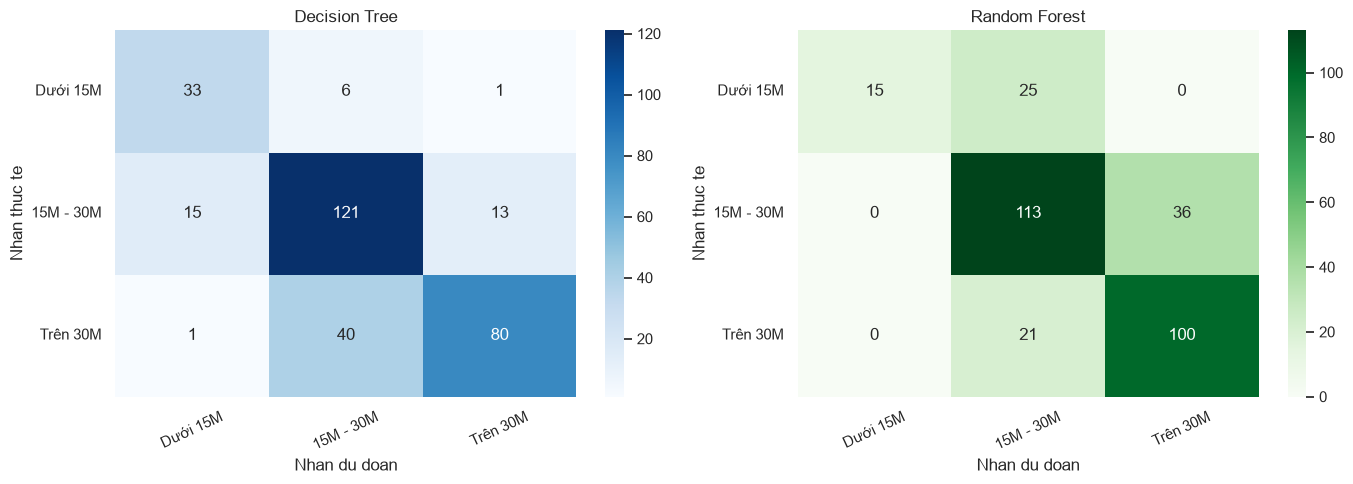

In [23]:

# ============================================
# 2.6.2. MA TRẬN NHẦM LẪN
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Bước 1: Xác định thứ tự các nhóm lương
labels = [
    "Dưới 15M",
    "15M - 30M",
    "Trên 30M"
]

# Bước 2: Tính Confusion Matrix cho Decision Tree
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=labels
)

# Bước 3: Tính Confusion Matrix cho Random Forest
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=labels
)

# Bước 4: Hiển thị kết quả dưới dạng bảng
print("CONFUSION MATRIX - DECISION TREE")
display(pd.DataFrame(
    cm_dt,
    index=labels,
    columns=labels
))

print("\nCONFUSION MATRIX - RANDOM FOREST")
display(pd.DataFrame(
    cm_rf,
    index=labels,
    columns=labels
))

# Bước 5: Vẽ biểu đồ ma trận nhầm lẫn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Decision Tree
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)

axes[0].set_title("Decision Tree")
axes[0].set_xlabel("Nhan du doan")
axes[0].set_ylabel("Nhan thuc te")

# Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Nhan du doan")
axes[1].set_ylabel("Nhan thuc te")

# Điều chỉnh giao diện
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()



#### Nhận xét

**1. Đối với mô hình Decision Tree**

- Mô hình dự đoán đúng 234/310 tin tuyển dụng,
  tương ứng với Accuracy đạt 75,48%.

- Nhóm Dưới 15M có 33/40 tin được phân loại
  chính xác, tương ứng Recall đạt 82,5%.

- Nhóm 15M - 30M có 121/149 tin được phân loại
  chính xác.

- Nhóm Trên 30M có 80/121 tin được phân loại
  chính xác. Trong đó, 40 tin bị nhầm
  sang nhóm 15M - 30M.

- Kết quả cho thấy Decision Tree phân loại
  khá tốt nhóm Dưới 15M và 15M - 30M,
  nhưng còn nhầm lẫn đáng kể giữa nhóm
  Trên 30M và nhóm 15M - 30M.

**2. Đối với mô hình Random Forest**

- Mô hình dự đoán đúng 228/310 tin tuyển dụng,
  tương ứng với Accuracy đạt 73,55%.

- Nhóm Dưới 15M chỉ có 15/40 tin được
  phân loại chính xác, trong khi 25 tin
  bị nhầm sang nhóm 15M - 30M.

- Nhóm 15M - 30M có 113/149 tin được
  phân loại chính xác, 36 tin bị nhầm
  sang nhóm Trên 30M.

- Nhóm Trên 30M có 100/121 tin được
  phân loại chính xác, tương ứng Recall
  đạt khoảng 82,64%.

- Random Forest nhận diện tốt hơn nhóm
  Trên 30M nhưng bỏ sót nhiều tin thuộc
  nhóm Dưới 15M.

**3. So sánh hai mô hình**

- Decision Tree dự đoán đúng nhiều hơn
  Random Forest 6 tin tuyển dụng.

- Decision Tree có khả năng nhận diện
  nhóm Dưới 15M tốt hơn đáng kể.

- Random Forest có khả năng nhận diện
  nhóm Trên 30M tốt hơn Decision Tree.

- Các nhầm lẫn chủ yếu xảy ra giữa
  những nhóm lương liền kề nhau.

**Kết luận:**

Qua phân tích Confusion Matrix, Decision Tree
cho kết quả phân lớp tương đối cân bằng hơn
giữa ba nhóm lương, trong khi Random Forest
có ưu thế đối với nhóm Trên 30M.

Tuy nhiên, cả hai mô hình đều còn xuất hiện
những nhầm lẫn đáng kể. Vì vậy, cần tiếp tục
phân tích các đặc trưng quan trọng, kiểm tra
overfitting và tối ưu tham số mô hình.

Các kết quả trên được tính theo nhãn lương
đã xử lý, bao gồm cả những nhãn được nội suy,
nên chưa phản ánh đầy đủ độ chính xác dự đoán
lương thực tế.



### 2.6.3. Trực quan hóa cây quyết định

Để phân tích cách thức mô hình Decision Tree
đưa ra kết quả dự đoán, tiến hành trực quan
hóa cấu trúc cây quyết định đã được huấn luyện.

Sử dụng hàm `plot_tree()` trong thư viện
scikit-learn để biểu diễn các nút phân chia
và những quy tắc được mô hình học từ dữ liệu.

Các thông tin được hiển thị tại mỗi nút:

- **Feature:** Thuộc tính được sử dụng để chia dữ liệu.
- **Gini:** Mức độ hỗn tạp giữa các lớp.
- **Samples:** Số lượng quan sát tại nút.
- **Value:** Phân bố các nhóm lương tại nút.
- **Class:** Nhóm lương được dự đoán.

Do cây quyết định có độ sâu tối đa bằng 5,
chỉ hiển thị ba mức đầu tiên (từ độ sâu 0 đến 2)
để dễ dàng quan sát và phân tích.

Mục tiêu là xác định các thuộc tính được
sử dụng ở những nút đầu tiên và giải thích
cách mô hình phân chia các nhóm lương.


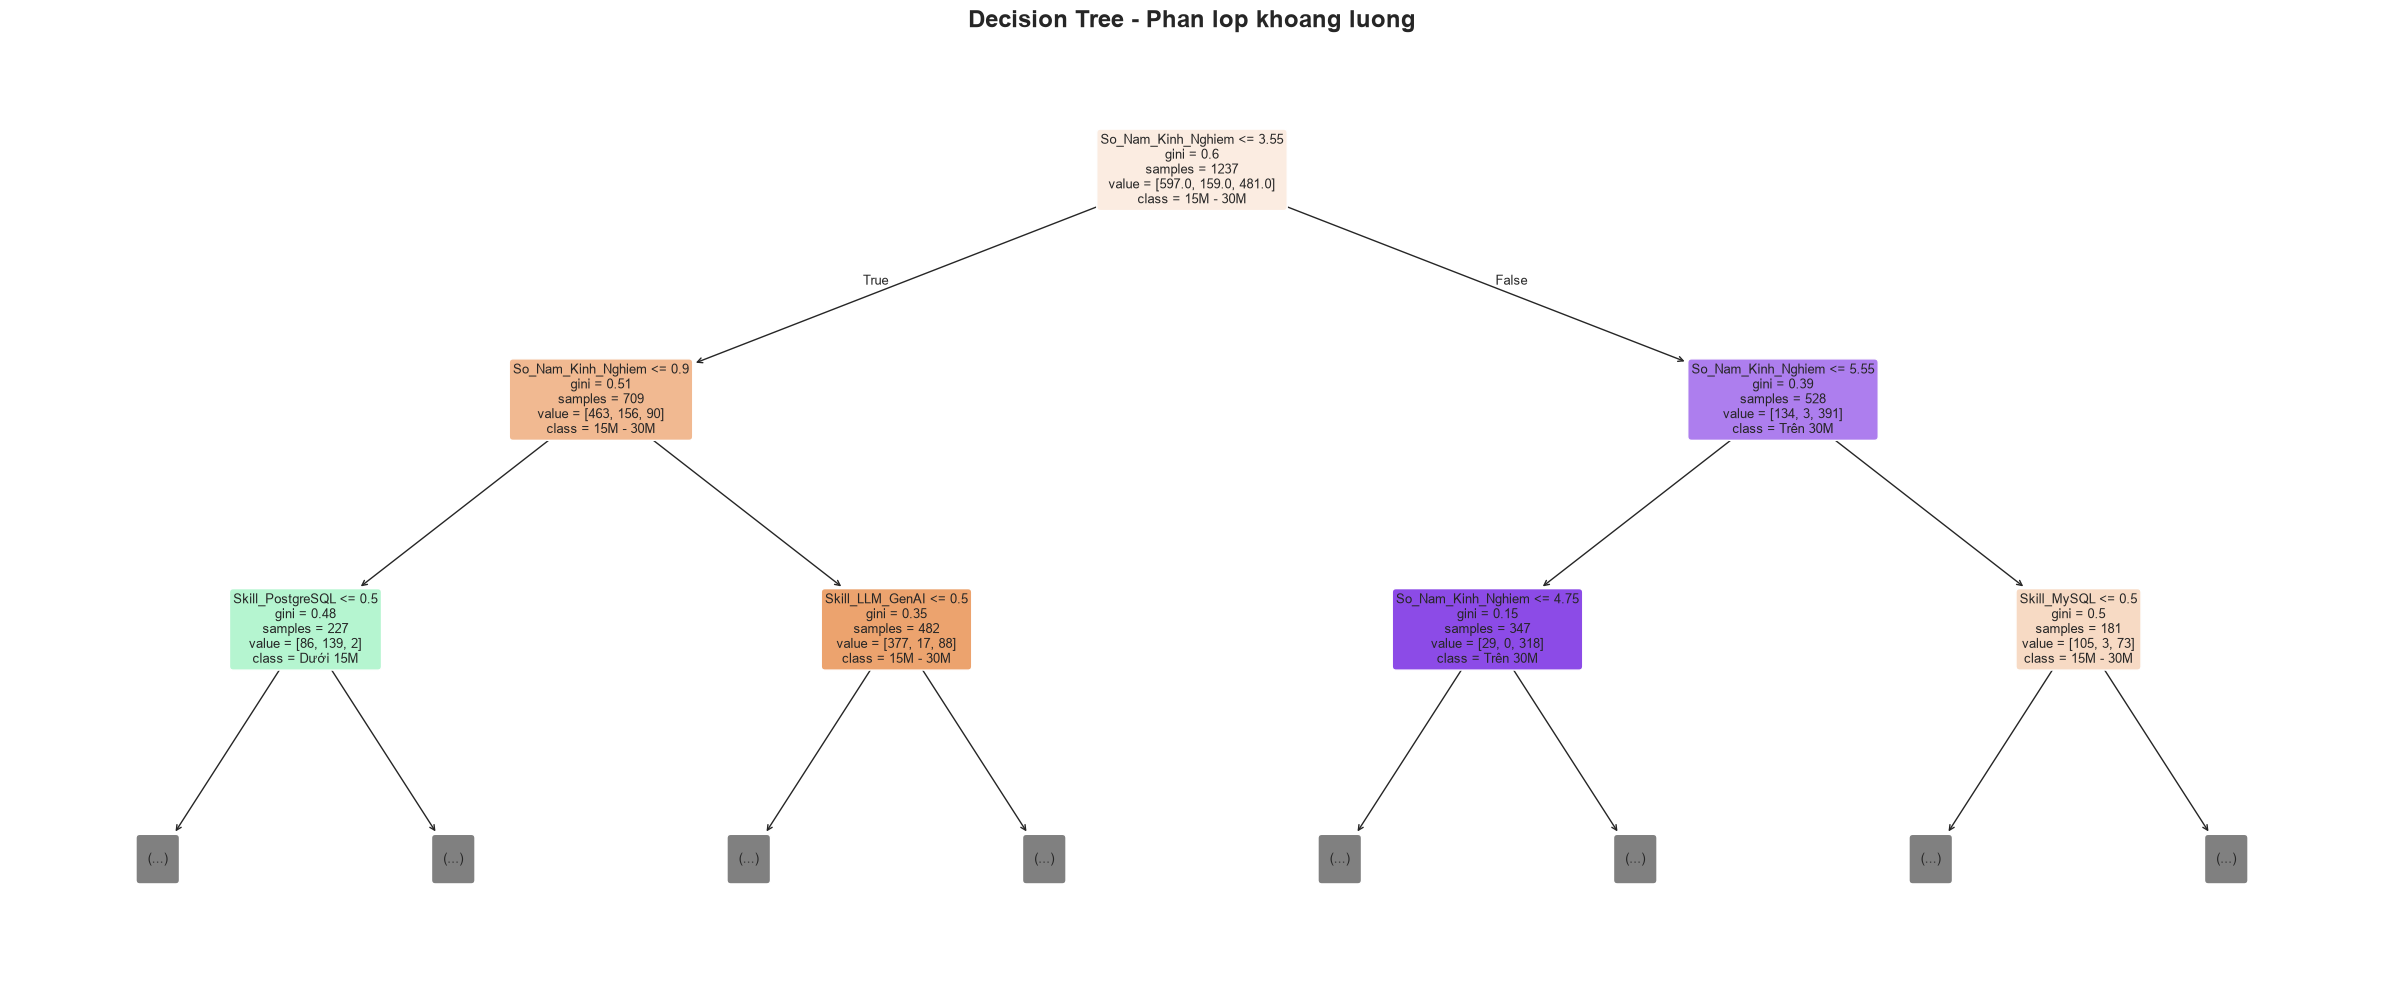

Đã lưu hình tại: D:\project_datamining\crawl-data-job-it-\notebooks\outputs\decision_tree.png


In [24]:

# ============================================
# 2.6.3. TRỰC QUAN HÓA DECISION TREE
# ============================================

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from pathlib import Path

# Bước 1: Tạo khung hình
fig, ax = plt.subplots(figsize=(24, 10))

# Bước 2: Vẽ cây quyết định
plot_tree(
    dt_model,
    feature_names=X_train.columns.tolist(),
    class_names=dt_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=2,
    impurity=True,
    precision=2,
    ax=ax
)

# Bước 3: Đặt tiêu đề biểu đồ
ax.set_title(
    "Decision Tree - Phan lop khoang luong",
    fontsize=17,
    fontweight="bold",
    pad=20
)

# Bước 4: Điều chỉnh bố cục
plt.tight_layout()

# Bước 5: Lưu hình để đưa vào báo cáo
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

image_path = output_dir / "decision_tree.png"

fig.savefig(
    image_path,
    dpi=200,
    bbox_inches="tight"
)

# Bước 6: Hiển thị hình
plt.show()

print("Đã lưu hình tại:", image_path.resolve())


## RÚT TRÍCH QUY TẮC TỪ DECISION TREE

In [25]:

# ============================================
# RÚT TRÍCH QUY TẮC TỪ DECISION TREE
# ============================================

from sklearn.tree import export_text

# Bước 1: Lấy quy tắc các mức đầu tiên
rules = export_text(
    dt_model,
    feature_names=X_train.columns.tolist(),
    max_depth=2,
    decimals=2
)

# Bước 2: Hiển thị quy tắc
print("CÁC QUY TẮC PHÂN CHIA:")
print(rules)

# Bước 3: Kiểm tra đặc trưng tại nút gốc
root_feature_index = dt_model.tree_.feature[0]
root_feature = X_train.columns[root_feature_index]
root_threshold = dt_model.tree_.threshold[0]

print("\nThuộc tính nút gốc:", root_feature)
print(f"Ngưỡng phân chia: {root_threshold:.2f}")

# Bước 4: Kiểm tra thứ tự các lớp
print("\nThứ tự các nhóm lương:")
print(dt_model.classes_)


CÁC QUY TẮC PHÂN CHIA:
|--- So_Nam_Kinh_Nghiem <= 3.55
|   |--- So_Nam_Kinh_Nghiem <= 0.90
|   |   |--- Skill_PostgreSQL <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Skill_PostgreSQL >  0.50
|   |   |   |--- truncated branch of depth 3
|   |--- So_Nam_Kinh_Nghiem >  0.90
|   |   |--- Skill_LLM_GenAI <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Skill_LLM_GenAI >  0.50
|   |   |   |--- truncated branch of depth 3
|--- So_Nam_Kinh_Nghiem >  3.55
|   |--- So_Nam_Kinh_Nghiem <= 5.55
|   |   |--- So_Nam_Kinh_Nghiem <= 4.75
|   |   |   |--- truncated branch of depth 3
|   |   |--- So_Nam_Kinh_Nghiem >  4.75
|   |   |   |--- truncated branch of depth 3
|   |--- So_Nam_Kinh_Nghiem >  5.55
|   |   |--- Skill_MySQL <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Skill_MySQL >  0.50
|   |   |   |--- truncated branch of depth 2


Thuộc tính nút gốc: So_Nam_Kinh_Nghiem
Ngưỡng phân chia: 3.55

Thứ tự các nhóm lương:
['15M - 30M' 'Dưới 15M' '


#### Nhận xét

Sau khi trực quan hóa mô hình Decision Tree,
có thể rút ra những nhận xét sau:

**1. Cấu trúc cây quyết định**

- Mô hình có độ sâu thực tế bằng 5 và
  tổng cộng 27 nút lá.
- Cấu trúc cây thể hiện các điều kiện
  phân chia được học từ dữ liệu huấn luyện.
- Mỗi nút sử dụng một thuộc tính và một
  ngưỡng phân chia để tách dữ liệu.

**2. Các thuộc tính được lựa chọn**

- Thuộc tính `So_Nam_Kinh_Nghiem` xuất hiện
  tại nút gốc với ngưỡng phân chia 3,55 năm.
- Những nút tiếp theo tiếp tục sử dụng
  số năm kinh nghiệm để phân chia dữ liệu.
- Một số thuộc tính kỹ năng như
  `Skill_PostgreSQL` và `Skill_LLM_GenAI`
  cũng được sử dụng trong các nhánh của cây.

**3. Ý nghĩa của các quy tắc**

- Các điều kiện phân chia cho thấy mô hình
  sử dụng thông tin kinh nghiệm và kỹ năng
  để phân biệt những nhóm lương khác nhau.
- Việc một thuộc tính được chọn tại nút gốc
  cho thấy thuộc tính đó có vai trò quan trọng
  trong phép chia đầu tiên của mô hình.
- Các quy tắc được rút trích giúp giải thích
  quá trình đưa ra dự đoán của Decision Tree.

**Kết luận:**

Việc trực quan hóa Decision Tree giúp làm rõ
cách mô hình phân chia dữ liệu tuyển dụng
thành các nhóm lương.

Kết quả bước đầu cho thấy số năm kinh nghiệm
được sử dụng tại các nút đầu tiên của cây,
bên cạnh một số kỹ năng công nghệ.

Tuy nhiên, các quy tắc chỉ phản ánh mối
quan hệ mà mô hình học được từ bộ dữ liệu
đã xử lý, không chứng minh quan hệ nhân quả
giữa kỹ năng, kinh nghiệm và mức lương.

Cần tiếp tục phân tích Feature Importance
để đánh giá mức độ đóng góp của các thuộc
tính đầu vào trong quá trình phân lớp.



### 2.6.4. Phân tích mức độ quan trọng của các đặc trưng (Feature Importance)

Feature Importance là chỉ số phản ánh mức độ
đóng góp của từng thuộc tính đầu vào trong
quá trình phân lớp của mô hình.

Trong nghiên cứu này, Feature Importance được
sử dụng để xác định:

- Mức độ đóng góp của số năm kinh nghiệm
  trong việc dự đoán khoảng lương.
- Những kỹ năng công nghệ có mức độ quan trọng
  cao trong mô hình Decision Tree.
- Những kỹ năng công nghệ có mức độ quan trọng
  cao trong mô hình Random Forest.

Sử dụng thuộc tính `feature_importances_`
để trích xuất mức độ quan trọng của 61
đặc trưng đã được đưa vào huấn luyện.

Kết quả được trình bày dưới dạng bảng
xếp hạng và biểu đồ cột.

Ngoài ra, tiến hành phân tích riêng các
tin tuyển dụng thuộc nhóm lương Trên 30M
để xác định những kỹ năng thường xuất hiện
và có liên hệ với nhóm lương cao.


In [26]:

# ============================================
# 2.6.4. PHÂN TÍCH FEATURE IMPORTANCE
# ============================================

import pandas as pd

# Bước 1: Lấy Feature Importance của Decision Tree
importance_dt = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Bước 2: Lấy Feature Importance của Random Forest
importance_rf = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Bước 3: Hiển thị 10 thuộc tính quan trọng nhất
print("TOP 10 FEATURE IMPORTANCE - DECISION TREE")
display(importance_dt.head(10).to_frame("Importance"))

print("\nTOP 10 FEATURE IMPORTANCE - RANDOM FOREST")
display(importance_rf.head(10).to_frame("Importance"))


TOP 10 FEATURE IMPORTANCE - DECISION TREE


,Importance
So_Nam_Kinh_Nghiem,0.762197
Skill_LLM_GenAI,0.064174
Skill_PostgreSQL,0.038820
Skill_Linux,0.031235
Skill_MySQL,0.025576
Skill_Java,0.024832
Skill_Cloud_Azure,0.012457
Skill_Python,0.011766
Skill_PowerBI,0.010776
Skill_Machine_Learning,0.007351



TOP 10 FEATURE IMPORTANCE - RANDOM FOREST


,Importance
So_Nam_Kinh_Nghiem,0.533973
Skill_Machine_Learning,0.047525
Skill_LLM_GenAI,0.040802
Skill_Python,0.014594
Skill_CI_CD,0.014174
Skill_SQL_Server,0.014109
Skill_Linux,0.013767
Skill_Communication,0.013605
Skill_Oracle,0.013370
Skill_Teamwork,0.012982


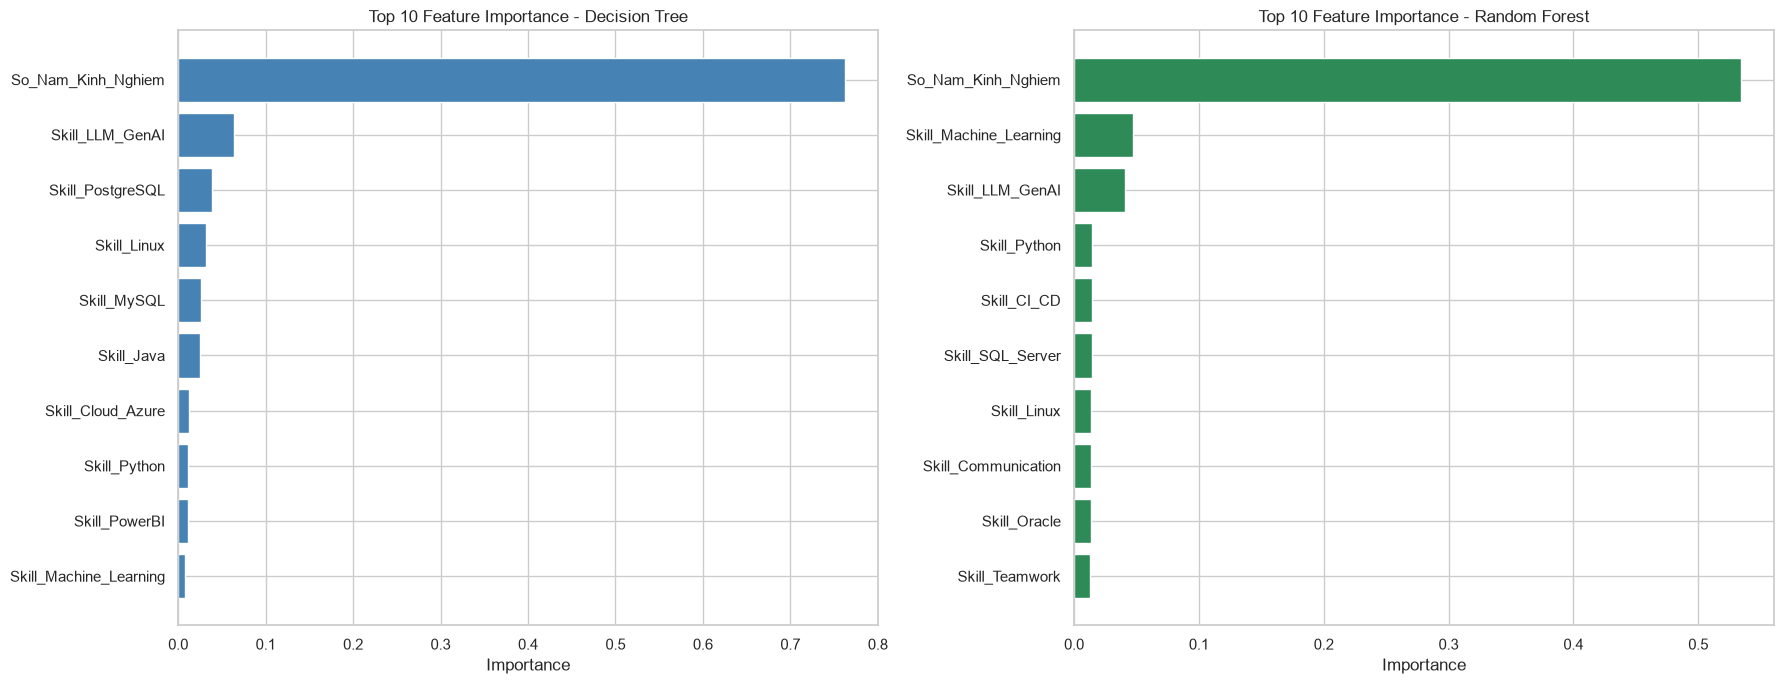

In [27]:

# ============================================
# VẼ BIỂU ĐỒ FEATURE IMPORTANCE
# ============================================

import matplotlib.pyplot as plt
from pathlib import Path

# Bước 1: Lấy 10 đặc trưng quan trọng nhất
top_dt = importance_dt.head(10).sort_values()
top_rf = importance_rf.head(10).sort_values()

# Bước 2: Tạo hai biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Decision Tree
axes[0].barh(
    top_dt.index,
    top_dt.values,
    color="steelblue"
)

axes[0].set_title(
    "Top 10 Feature Importance - Decision Tree"
)
axes[0].set_xlabel("Importance")

# Random Forest
axes[1].barh(
    top_rf.index,
    top_rf.values,
    color="seagreen"
)

axes[1].set_title(
    "Top 10 Feature Importance - Random Forest"
)
axes[1].set_xlabel("Importance")

# Bước 3: Điều chỉnh bố cục
plt.tight_layout()

# Bước 4: Lưu biểu đồ
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / "feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

# Bước 5: Hiển thị
plt.show()


In [28]:

# ============================================
# PHÂN TÍCH KỸ NĂNG LIÊN QUAN LƯƠNG TRÊN 30M
# ============================================

# Bước 1: Xác định nhóm lương cao
luong_cao = df["Khoang_Luong_Phan_Lop"] == "Trên 30M"

# Bước 2: Thống kê từng kỹ năng
ket_qua_ky_nang = []

for skill in skill_cols:

    # Các tin yêu cầu kỹ năng
    co_ky_nang = df[skill] == 1

    # Tổng số tin yêu cầu kỹ năng
    tong_so = co_ky_nang.sum()

    # Số tin vừa yêu cầu kỹ năng vừa thuộc Trên 30M
    so_luong_cao = (co_ky_nang & luong_cao).sum()

    # Tính tỷ lệ thuộc nhóm lương cao
    ty_le = (
        so_luong_cao / tong_so * 100
        if tong_so > 0 else 0
    )

    ket_qua_ky_nang.append({
        "Ky_Nang": skill.replace("Skill_", ""),
        "So_Tin_Co_Ky_Nang": tong_so,
        "So_Tin_Tren_30M": so_luong_cao,
        "Ty_Le_Tren_30M": ty_le
    })

# Bước 3: Tạo bảng thống kê
bang_ky_nang = pd.DataFrame(ket_qua_ky_nang)

# Bước 4: Chỉ xét kỹ năng xuất hiện từ 30 tin
bang_ky_nang = bang_ky_nang[
    bang_ky_nang["So_Tin_Co_Ky_Nang"] >= 30
]

# Bước 5: Sắp xếp theo tỷ lệ lương cao
bang_ky_nang = bang_ky_nang.sort_values(
    "Ty_Le_Tren_30M",
    ascending=False
)

# Bước 6: Hiển thị 10 kỹ năng đứng đầu
print("TOP 10 KỸ NĂNG LIÊN QUAN LƯƠNG TRÊN 30M")

display(bang_ky_nang.head(10).round(2))


TOP 10 KỸ NĂNG LIÊN QUAN LƯƠNG TRÊN 30M


,Ky_Nang,So_Tin_Co_Ky_Nang,So_Tin_Tren_30M,Ty_Le_Tren_30M
31,NLP,54,37,68.52
34,MLOps,58,39,67.24
25,Deep_Learning,73,49,67.12
24,Machine_Learning,245,153,62.45
30,TensorFlow,42,26,61.90
32,Computer_Vision,72,43,59.72
13,AB_Testing,34,20,58.82
33,LLM_GenAI,258,150,58.14
29,PyTorch,50,29,58.00
12,Statistics,158,81,51.27



#### Nhận xét

**1. Phân tích Feature Importance**

- Trong cả hai mô hình Decision Tree và
  Random Forest, số năm kinh nghiệm là
  thuộc tính có mức độ quan trọng cao nhất.

- Đối với Decision Tree, số năm kinh nghiệm
  chiếm khoảng 76,22% tổng Feature Importance.

- Đối với Random Forest, số năm kinh nghiệm
  chiếm khoảng 53,40% tổng Feature Importance.

- Trong nhóm kỹ năng công nghệ, Decision Tree
  đánh giá cao LLM/GenAI, PostgreSQL và Linux.

- Random Forest đánh giá cao Machine Learning,
  LLM/GenAI và Python.

**2. Các kỹ năng liên quan đến lương Trên 30M**

- NLP có tỷ lệ tin thuộc nhóm Trên 30M cao nhất
  trong nhóm kỹ năng được xét, đạt 68,52%.

- MLOps và Deep Learning cũng có tỷ lệ cao,
  lần lượt đạt 67,24% và 67,12%.

- Machine Learning xuất hiện trong 153 tin
  thuộc nhóm Trên 30M, với tỷ lệ 62,45%
  trong các tin có yêu cầu kỹ năng này.

- LLM/GenAI xuất hiện trong 150 tin thuộc
  nhóm Trên 30M, với tỷ lệ 58,14%.

- Các kỹ năng chuyên sâu về AI và Machine
  Learning có mối liên hệ đáng chú ý với
  nhóm lương cao trong bộ dữ liệu.

**3. Kết luận**

Kết quả Feature Importance cho thấy số năm
kinh nghiệm đóng góp lớn vào quá trình
phân lớp khoảng lương của cả hai mô hình.

Bên cạnh đó, Machine Learning và LLM/GenAI
là những kỹ năng đáng chú ý vì vừa có
Feature Importance tương đối cao trong
mô hình, vừa xuất hiện trong nhiều tin
tuyển dụng thuộc nhóm Trên 30M.

Những kết quả này có thể được sử dụng
làm cơ sở thảo luận và xây dựng khuyến nghị
định hướng nghề nghiệp cho sinh viên
ngành Dữ liệu/CNTT.

Tuy nhiên, các kết quả phản ánh mối liên hệ
trong dữ liệu tuyển dụng đã xử lý, không
khẳng định kỹ năng là nguyên nhân trực tiếp
quyết định mức lương.

Đặc biệt, một phần lớn nhãn lương được
nội suy từ dữ liệu lương thỏa thuận,
nên cần thận trọng khi diễn giải kết quả.



# 3. THẢO LUẬN VÀ KHUYẾN NGHỊ

## 3.1. Tổng hợp kết quả nghiên cứu

Sau quá trình thu thập, làm sạch, khai phá dữ liệu
và xây dựng mô hình học máy, nghiên cứu đã thu
được những kết quả về đặc điểm thị trường tuyển
dụng và yêu cầu kỹ năng trong ngành Dữ liệu/CNTT.

Bộ dữ liệu nghiên cứu gồm 1.547 tin tuyển dụng
thuộc 5 nhóm ngành Data.

Các phương pháp phân tích được sử dụng bao gồm:

- Phân tích khám phá dữ liệu (EDA).
- Phân cụm nghề nghiệp bằng K-Means.
- Khai phá luật kết hợp bằng Apriori.
- Phân lớp bằng Decision Tree và Random Forest.

Kết quả nghiên cứu được tổng hợp nhằm làm rõ
nhu cầu kỹ năng, sự khác biệt giữa các nhóm
nghề nghiệp và mối liên hệ giữa kỹ năng,
kinh nghiệm với khoảng lương tuyển dụng.

Các kết quả cũng là cơ sở để đề xuất định hướng
học tập và phát triển nghề nghiệp cho sinh viên
chuyên ngành Dữ liệu và Công nghệ thông tin.



## 3.2. Thảo luận kết quả mô hình phân lớp

### 3.2.1. So sánh Decision Tree và Random Forest

Hai mô hình Decision Tree và Random Forest
được huấn luyện trên tập Train gồm 1.237
quan sát và đánh giá trên tập Test gồm
310 quan sát.

Kết quả thực nghiệm:

| Chỉ số | Decision Tree | Random Forest |
|---|---:|---:|
| Accuracy | 75,48% | 73,55% |
| Macro Precision | 74,97% | 81,53% |
| Macro Recall | 76,61% | 65,33% |
| Macro F1-score | 75,05% | 68,58% |

**Nhận xét:**

- Decision Tree đạt Accuracy cao hơn Random
  Forest khoảng 1,94 điểm phần trăm.

- Decision Tree có Macro F1-score cao hơn,
  cho thấy sự cân bằng tốt hơn giữa
  Precision và Recall trên ba nhóm lương.

- Random Forest đạt Macro Precision cao hơn
  nhưng Macro Recall thấp hơn Decision Tree.

- Qua Confusion Matrix, Decision Tree nhận
  diện tốt hơn hai nhóm Dưới 15M và
  15M - 30M.

- Random Forest nhận diện tốt hơn nhóm
  Trên 30M với 100/121 tin được dự đoán đúng.

Trong hai cấu hình thử nghiệm hiện tại,
Decision Tree cho kết quả tổng thể tốt hơn
theo Accuracy và Macro F1-score.

Tuy nhiên, kết quả này chưa đủ để khẳng định
Decision Tree luôn tốt hơn Random Forest.

### 3.2.2. Vai trò của kinh nghiệm và kỹ năng

Kết quả Feature Importance cho thấy
số năm kinh nghiệm là thuộc tính có
mức độ quan trọng cao nhất trong cả
hai mô hình phân lớp.

Cụ thể:

- Decision Tree: khoảng 76,22%.
- Random Forest: khoảng 53,40%.

Bên cạnh kinh nghiệm, các kỹ năng như
Machine Learning, LLM/GenAI, PostgreSQL
và Linux cũng có đóng góp vào quá trình
phân lớp của mô hình.

Kết quả phân tích nhóm lương Trên 30M
cho thấy một số kỹ năng chuyên sâu
có tỷ lệ thuộc nhóm lương cao đáng chú ý:

- NLP: 68,52%.
- MLOps: 67,24%.
- Deep Learning: 67,12%.
- Machine Learning: 62,45%.
- LLM/GenAI: 58,14%.

Những tỷ lệ trên được tính trong các tin
có yêu cầu từng kỹ năng, với điều kiện
mỗi kỹ năng xuất hiện trong ít nhất 30 tin.

Kết quả gợi ý rằng kinh nghiệm và một số
kỹ năng chuyên môn có mối liên hệ với
việc phân loại khoảng lương trong dữ liệu.

Tuy nhiên, Feature Importance và tỷ lệ
xuất hiện không chứng minh quan hệ nhân quả
giữa một kỹ năng và mức lương.



## 3.3. Hạn chế của nghiên cứu

Mặc dù đã thu được các kết quả về kỹ năng,
kinh nghiệm và khoảng lương, nghiên cứu
vẫn tồn tại một số hạn chế:

- Bộ dữ liệu gồm 1.547 tin tuyển dụng,
  chưa đại diện cho toàn bộ thị trường
  lao động ngành Dữ liệu/CNTT.

- Có 1.156 tin tuyển dụng không công bố
  mức lương cụ thể, chiếm khoảng 74,7%
  tổng số quan sát.

- Các tin không công bố mức lương được
  xử lý bằng phương pháp nội suy giá trị
  lương và gán nhãn khoảng lương.

- Vì vậy, kết quả phân lớp phản ánh khả năng
  dự đoán nhãn đã xử lý, chưa thể khẳng định
  độ chính xác tương ứng đối với mức lương
  thực tế của thị trường.

- Các kỹ năng và số năm kinh nghiệm
  có thể liên quan đến mức lương, nhưng
  kết quả mô hình không chứng minh
  quan hệ nhân quả.

## 3.4. Kết luận chung

Nghiên cứu đã phân tích dữ liệu tuyển dụng
ngành Data nhằm khám phá nhu cầu kỹ năng,
đặc điểm nghề nghiệp và mối liên hệ
giữa kỹ năng, kinh nghiệm với khoảng lương.

Thông qua các phương pháp EDA, K-Means,
Apriori, Decision Tree và Random Forest,
nhóm đã thu được những kết quả chính:

- Xác định các kỹ năng phổ biến trên
  thị trường tuyển dụng ngành Data.

- Khám phá ba nhóm chân dung nghề nghiệp
  thông qua phân cụm K-Means.

- Phát hiện những mối liên kết giữa các
  kỹ năng thông qua thuật toán Apriori.

- Xây dựng hai mô hình Decision Tree và
  Random Forest để phân lớp khoảng lương.

- Trong hai cấu hình thử nghiệm, Decision Tree
  đạt Accuracy 75,48%, cao hơn Random Forest
  với Accuracy 73,55%.

- Số năm kinh nghiệm có Feature Importance
  cao nhất trong cả hai mô hình phân lớp.

- Một số kỹ năng chuyên sâu như NLP,
  MLOps, Deep Learning, Machine Learning
  và LLM/GenAI có mối liên hệ đáng chú ý
  với nhóm lương Trên 30M.

Từ những kết quả trên, nghiên cứu gợi ý định hướng nghề nghiệp theo 3 hướng chính: General Data & Analytics,
AI & Machine Learning và
Data Engineering & Infrastructure.

Kết quả cung cấp thông tin tham khảo
giúp sinh viên lựa chọn kỹ năng và
định hướng phát triển nghề nghiệp
phù hợp với năng lực, sở thích và
mục tiêu cá nhân.
